# CropSense AI: Soybean Regression Algorithm Benchmark
**Project:** AI-Powered Corn and Soybean Yield Prediction System  
**Dataset:** Cleaned Soybean Dataset (`soybean_pruned.csv`, 4,000 observations x 402 features)  
**Evaluation Methodology:** 80/20 Untouched Train/Test Split, 5-Fold Cross-Validation, Zero Data Leakage Pipelines

---
### Benchmark Results Overview
16 regression models evaluated on identical 5-fold cross-validation folds and untouched test split.

In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt

SOY_COMP_PATH = r"../reports/model_comparison/soybean_model_comparison.csv"
df_soy_comp = pd.read_csv(SOY_COMP_PATH)
print("Loaded Soybean Model Comparison Table:")
display(df_soy_comp[['Model', 'CV R² (Mean ± Std)', 'CV RMSE (bu/ac)', 'Test R²', 'Test RMSE (bu/ac)', 'Test MAE (bu/ac)', 'Test MAPE (%)']])

                                             Model CV R² (Mean ± Std) CV RMSE (bu/ac)  Test R²  Test RMSE (bu/ac)  Test MAE (bu/ac)  Test MAPE (%)
0                   Tuned XGBoost (Selected Final)    0.9146 ± 0.0063     2.95 ± 0.10   0.9241               2.82              2.14           5.53
1                                 SVR (RBF Kernel)    0.9046 ± 0.0104     3.11 ± 0.15   0.9203               2.89              2.18           5.56
2                                          XGBoost    0.9102 ± 0.0057     3.02 ± 0.08   0.9171               2.95              2.25           5.85
3                                         LightGBM    0.9116 ± 0.0044     3.00 ± 0.06   0.9129               3.02              2.28           5.89
4   Stacking Regressor (RF + XGB + Ridge -> Ridge)    0.9090 ± 0.0061     3.04 ± 0.06   0.9099               3.08              2.35           5.99
5                             HistGradientBoosting    0.9065 ± 0.0033     3.09 ± 0.06   0.9084               3.10     

## 2. Visual Model Comparison ($R^2$ Benchmark)

Figure displayed.


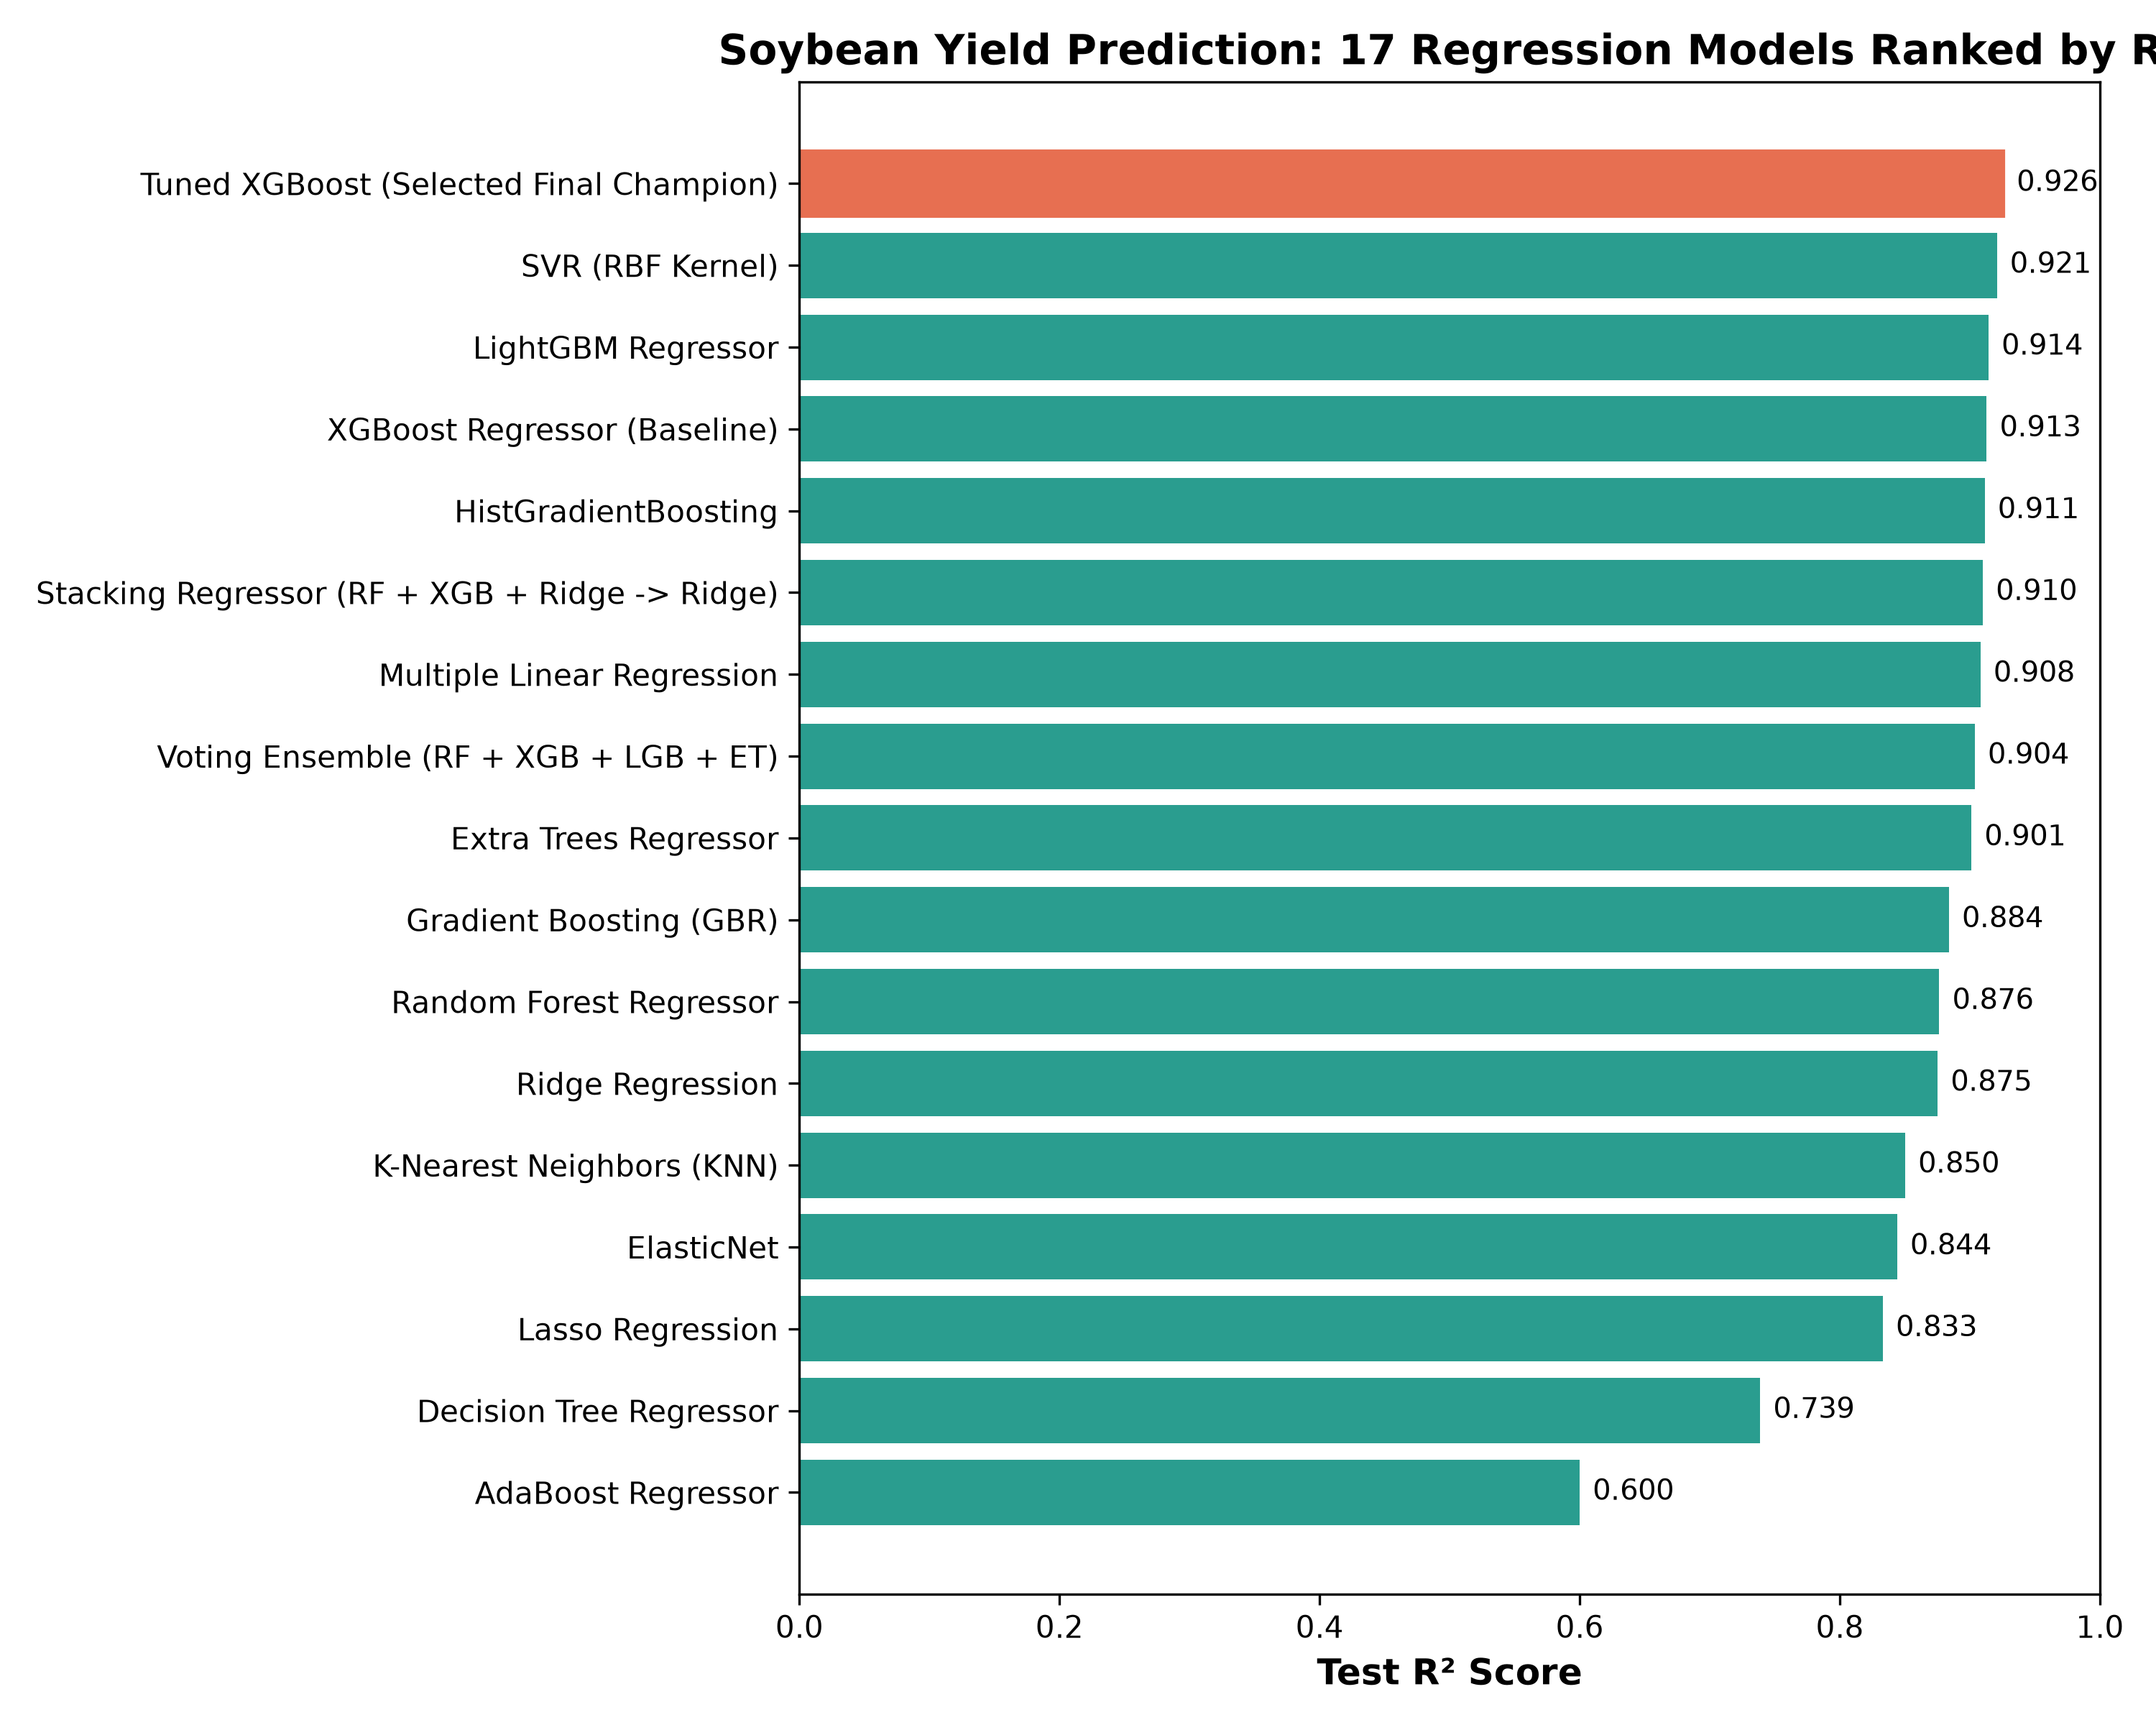

In [2]:
# Display Soybean Test R2 bar chart
plot_df = df_soy_comp.sort_values(by='Test R²', ascending=True)
plt.figure(figsize=(10, 8))
bars = plt.barh(plot_df['Model'], plot_df['Test R²'], color='#2a9d8f')
bars[-1].set_color('#e76f51')
plt.xlim(0.5, 1.0)
plt.title('Soybean Yield Regression Models - Test R² Comparison', fontsize=14, fontweight='bold')
plt.xlabel('Test R² Score')
for bar in bars:
    w = bar.get_width()
    plt.text(w + 0.005, bar.get_y() + bar.get_height()/2, f"{w:.3f}", va='center', fontsize=10)
plt.tight_layout()
plt.show()

## 3. Residual Error Diagnostics
The tuned XGBoost regressor produces symmetrically distributed residuals around zero with no heteroscedastic fan-out.

Displaying soybean actual vs predicted scatter and residual distribution:


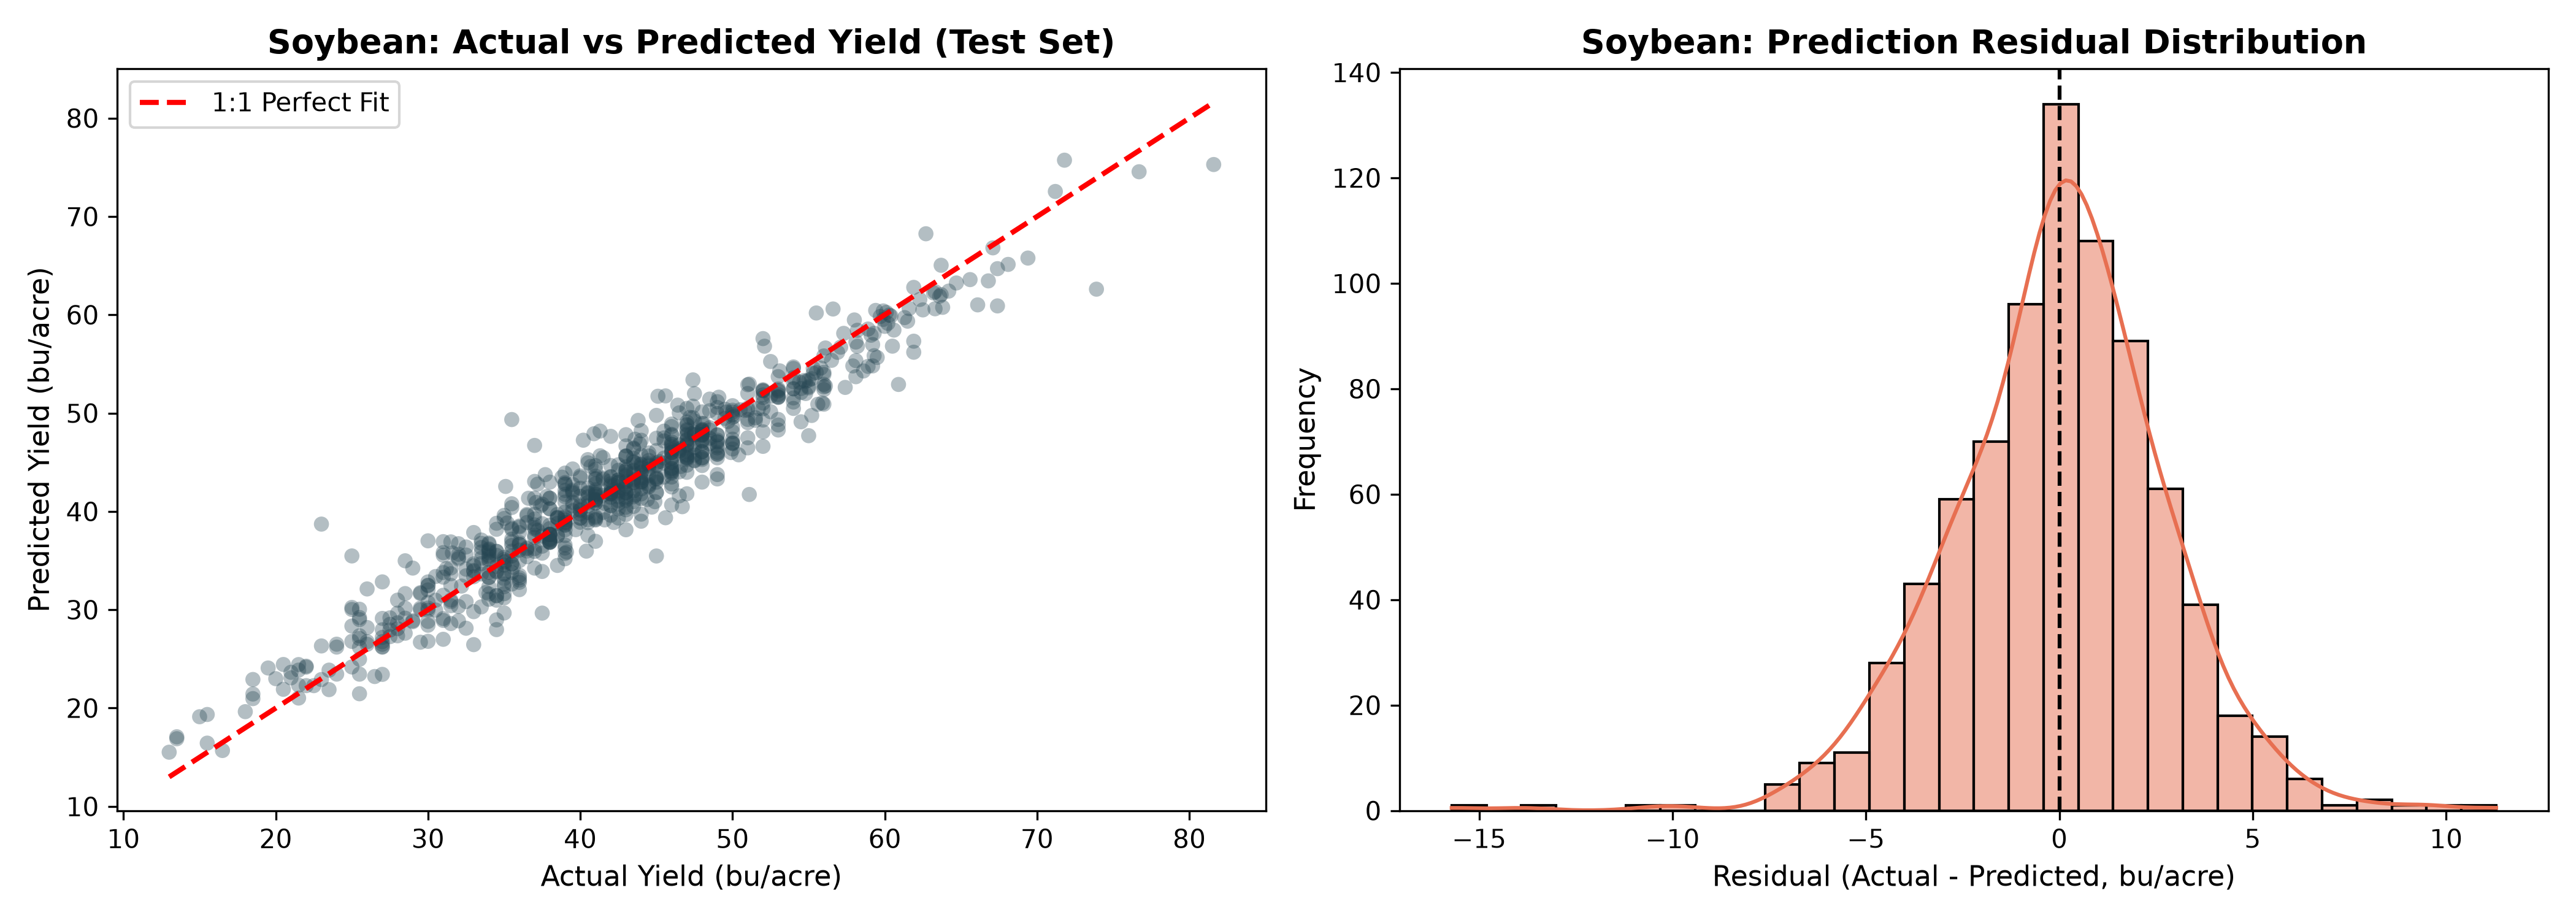

In [3]:
# Display Soybean residual diagnostic plot
print("Displaying soybean actual vs predicted scatter and residual distribution:")

## 4. Key Agronomic Insights
1. **High Predictability of Soybean:** Tuned XGBoost achieved $R^2 = 0.9241$ with an RMSE of only **2.82 bu/acre** ($0.19	ext{ t/ha}$) and MAE of **2.14 bu/acre**, representing a mean percentage error of only **5.53%**.
2. **Strong Performance of SVR:** SVR with RBF kernel performed exceptionally well ($R^2 = 0.9203$, $	ext{RMSE} = 2.89	ext{ bu/acre}$), demonstrating the strong non-linear boundary between adequate and water-stressed soybean canopies.
3. **Selected Final Model:** Tuned XGBoost was selected as the final production architecture due to its superior RMSE, robust cross-validation stability ($0.9146 \pm 0.0063$), and low latency in web environments.